Saving object_detection_sample.jpg to object_detection_sample (2).jpg


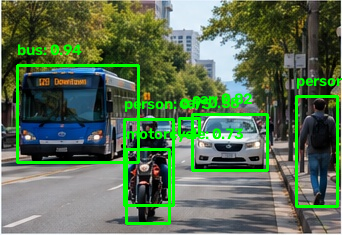

In [4]:
# PROGRAM 1 — EfficientDet (one-stage object detection)
# Install/import required packages
!pip -q install tensorflow-hub

import tensorflow_hub as hub
import tensorflow as tf
import numpy as np
import cv2
from google.colab import files
from google.colab.patches import cv2_imshow

# Load the pre-trained EfficientDet-D0 detector
MODEL_URL = "https://tfhub.dev/tensorflow/efficientdet/d0/1"
detector = hub.load(MODEL_URL)

# COCO class names (80 classes; the PDF had a placeholder in the middle)
COCO_CLASSES = [
    "person", "bicycle", "car", "motorcycle", "airplane", "bus", "train",
    "truck", "boat", "traffic light", "fire hydrant", "stop sign",
    "parking meter", "bench", "bird", "cat", "dog", "horse", "sheep", "cow",
    "elephant", "bear", "zebra", "giraffe", "backpack", "umbrella",
    "handbag", "tie", "suitcase", "frisbee", "skis", "snowboard",
    "sports ball", "kite", "baseball bat", "baseball glove", "skateboard",
    "surfboard", "tennis racket", "bottle", "wine glass", "cup", "fork",
    "knife", "spoon", "bowl", "banana", "apple", "sandwich", "orange",
    "broccoli", "carrot", "hot dog", "pizza", "donut", "cake", "chair",
    "couch", "potted plant", "bed", "dining table", "toilet", "tv",
    "laptop", "mouse", "remote", "keyboard", "cell phone", "microwave",
    "oven", "toaster", "sink", "refrigerator", "book", "clock", "vase",
    "scissors", "teddy bear", "hair drier", "toothbrush"
]

def detect_objects_with_boxes(image_path, detector):
    """Run the detector on an image and return it with labelled boxes."""
    image = cv2.imread(image_path)
    if image is None:
        raise ValueError("Could not read the image. Please upload a JPG or PNG image.")
    orig_image = image.copy()

    input_tensor = tf.convert_to_tensor(image)
    input_tensor = input_tensor[tf.newaxis, ...]

    detections = detector(input_tensor)
    num_detections = int(detections["num_detections"])
    detection_boxes = detections["detection_boxes"].numpy()[0]
    detection_classes = detections["detection_classes"].numpy()[0].astype(np.int32)
    detection_scores = detections["detection_scores"].numpy()[0]

    confidence_threshold = 0.5
    for i in range(num_detections):
        score = detection_scores[i]
        if score > confidence_threshold:
            y_min, x_min, y_max, x_max = detection_boxes[i]
            h, w, _ = orig_image.shape
            x_min, x_max = int(x_min * w), int(x_max * w)
            y_min, y_max = int(y_min * h), int(y_max * h)

            class_id = detection_classes[i]
            class_name = COCO_CLASSES[class_id - 1] if 1 <= class_id <= len(COCO_CLASSES) else "Unknown"
            label = f"{class_name}: {score:.2f}"
            cv2.rectangle(orig_image, (x_min, y_min), (x_max, y_max), (0, 255, 0), 2)
            cv2.putText(orig_image, label, (x_min, max(18, y_min - 10)),
                        cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0, 255, 0), 2)
    return orig_image

# Upload an image when prompted, then display the detected objects
uploaded = files.upload()
image_path = next(iter(uploaded))
result_image = detect_objects_with_boxes(image_path, detector)
cv2_imshow(result_image)